# Wave-Swin-GNN: Bone Fracture Detection
## Hybrid Model: Wavelet Transform + Swin Transformer V2 + Graph Neural Network

**Architecture:**
- **Dual-Path Design** — Wavelet path (high-frequency features) + Swin path (semantic features), fused via GNN
- **GPU-Native Haar DWT** — Implemented via `F.conv2d` for full GPU utilization
- **SwinV2-Tiny** — Window size 8, pretrained, fine-tuned (layers 0-2 frozen)
- **KNN-Graph GATv2** — K=6 spatial graph with multi-head attention and residual connections

**Combined Dataset:** GRAZPEDWRI-DX (~20,327 pediatric wrist X-rays) + Bone Fracture Multi-Region X-ray (~10,580 images) = ~30,907 total

**Target Metrics:** AP > 0.90, Recall > 80% at 85% precision, AUROC > 0.93, F1 > 0.85

In [2]:
# ==========================================
# CELL 1: SETUP & INSTALLATIONS
# ==========================================
import os
import gc
import random
import time
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch_geometric.nn import GATv2Conv
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc, roc_auc_score,
    precision_recall_curve, average_precision_score,
    classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)
from sklearn.model_selection import StratifiedShuffleSplit

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")
print(f"Random seed: {SEED}")

GPU: NVIDIA GeForce RTX 4060 Ti
Device: cuda
PyTorch: 2.10.0+cu128
Random seed: 42


## Cell 2: Combined Dataset Loader

Loads both **GRAZPEDWRI-DX** (pediatric wrist fractures, YOLO annotations) and **Bone Fracture Multi-Region X-ray** datasets into a unified pipeline with:
- YOLO annotation parsing for GRAZPEDWRI-DX binary classification (class 3 = fracture)
- 16-bit grayscale PNG handling (GRAZPEDWRI-DX images)
- Dual image integrity verification (PIL + OpenCV)
- CLAHE preprocessing
- Albumentations augmentation
- Stratified 70/15/15 split by label AND source
- Weighted random sampling for class balance

In [3]:
# ==========================================
# CELL 2: DATASET LOADER  (leakage-hardened)
# ==========================================
# CHANGES vs. original (addresses reviewer leakage concerns):
#   1. Exact + near-duplicate removal via average-hash BEFORE splitting.
#   2. Group-SAFE split: all variants of the same source image are forced
#      into the SAME split, so no image leaks across train/val/test.
#   3. Every sample tagged with 'source' + 'group' for per-source reporting.
#   4. Explicit zero-overlap assertion after splitting.
#
# HONEST LIMITATION: the Bone Fracture Multi-Region set has no patient IDs,
# so a *true* patient-level split is impossible for this source. Grouping by
# base-image + hash dedup is the strongest leakage control available here.
# If you add GRAZPEDWRI-DX, replace extract_group_id() with the real patient
# ID parsed from its filename (e.g. "0001_...png" -> patient "0001").
import os, re, cv2, hashlib
import torch
import numpy as np
from PIL import Image
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
import albumentations as A
from albumentations.pytorch import ToTensorV2

MULTIREGION_ROOT = "dataset/Bone_Fracture_Multi_Region"
SEED = 42

def verify_image(img_path):
    try:
        img = cv2.imread(img_path)
        if img is None:
            return False
        with Image.open(img_path) as pil_img:
            pil_img.load()
        return True
    except Exception:
        return False

# ---- Perceptual hash for duplicate detection (no extra deps) ----
def average_hash(img_path, hash_size=8):
    """64-bit average hash. Catches exact dupes, re-encodes, and resizes."""
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    small = cv2.resize(img, (hash_size, hash_size), interpolation=cv2.INTER_AREA)
    bits = (small > small.mean()).flatten()
    return ''.join('1' if b else '0' for b in bits)

# ---- Group ID: force variants of the same base image into one split ----
def extract_group_id(path, source):
    """
    Best-effort base-image identity so augmented copies stay together.
    Strips Roboflow ('.rf.<hex>') and common augmentation suffixes.
    NOTE: verify this matches your filenames; adjust the regex if needed.
    """
    stem = os.path.splitext(os.path.basename(path))[0].lower()
    stem = re.sub(r'\.rf\.[0-9a-f]+$', '', stem)              # roboflow hash
    stem = re.sub(r'[_-](aug|flip|rot\d*|copy|dup)\d*$', '', stem)  # aug tokens
    stem = re.sub(r'[_-]jpg$|[_-]png$|[_-]jpeg$', '', stem)   # roboflow ext token
    return f"{source}:{stem}"

def load_multiregion(root_dir):
    entries, corrupt_count = [], 0
    print("Loading Bone Fracture Multi-Region...")
    for split in ['train', 'val', 'test']:
        split_dir = os.path.join(root_dir, split)
        if not os.path.isdir(split_dir):
            continue
        for class_folder in os.listdir(split_dir):
            class_path = os.path.join(split_dir, class_folder)
            if not os.path.isdir(class_path):
                continue
            label = 1.0 if ('fractured' in class_folder.lower() and 'not' not in class_folder.lower()) else 0.0
            for img_file in os.listdir(class_path):
                img_path = os.path.join(class_path, img_file)
                if not img_file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
                    continue
                if verify_image(img_path):
                    entries.append({'path': img_path, 'label': label, 'source': 'MultiRegion'})
                else:
                    corrupt_count += 1
    print(f"  Multi-Region: {len(entries)} valid, {corrupt_count} corrupt removed")
    return entries, corrupt_count

all_data_raw, mr_corrupt = load_multiregion(MULTIREGION_ROOT)

# ---- Deduplicate (exact + near-duplicate by average hash) ----
print("\nDeduplicating via average-hash...")
seen_hashes, all_data, dup_count = {}, [], 0
for d in tqdm(all_data_raw):
    h = average_hash(d['path'])
    if h is None:
        continue
    if h in seen_hashes:
        dup_count += 1          # duplicate image -> drop (prevents cross-split leakage)
        continue
    seen_hashes[h] = True
    d['group'] = extract_group_id(d['path'], d['source'])
    all_data.append(d)
print(f"  Removed {dup_count} duplicate/near-duplicate images")

labels = [int(d['label']) for d in all_data]
groups = [d['group'] for d in all_data]
n_groups = len(set(groups))

print(f"\n--- Dataset Summary (post-dedup) ---")
print(f"Total images: {len(all_data)} | Unique groups: {n_groups}")
print(f"  Fractured: {sum(labels)} | Non-fractured: {len(labels)-sum(labels)}")

# ---- GROUP-SAFE stratified split (70/15/15), no group crosses splits ----
# Step 1: 70% train vs 30% temp, keeping groups intact + label balance.
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = list(sgkf.split(all_data, labels, groups))
# Use ~3 of 10 folds (~30%) as temp, rest as train.
temp_idx = np.concatenate([folds[i][1] for i in range(3)])
train_idx = np.array([i for i in range(len(all_data)) if i not in set(temp_idx.tolist())])

# Step 2: split temp -> val/test by GROUP (50/50), no group overlap.
temp_groups = [groups[i] for i in temp_idx]
temp_labels = [labels[i] for i in temp_idx]
gss = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
val_rel, test_rel = next(gss.split(temp_idx, temp_labels, temp_groups))
val_idx, test_idx = temp_idx[val_rel], temp_idx[test_rel]

train_data = [all_data[i] for i in train_idx]
val_data   = [all_data[i] for i in val_idx]
test_data  = [all_data[i] for i in test_idx]

# ---- LEAKAGE ASSERTION: zero group overlap across splits ----
g_tr, g_va, g_te = set(d['group'] for d in train_data), set(d['group'] for d in val_data), set(d['group'] for d in test_data)
assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te), "GROUP LEAKAGE DETECTED"
print("\n[OK] No group overlap across train/val/test (leakage check passed).")

print(f"\n--- Split Summary ---")
for name, split in [('Train', train_data), ('Val', val_data), ('Test', test_data)]:
    n_frac = sum(1 for d in split if d['label'] == 1)
    print(f"  {name}: {len(split)} imgs ({n_frac} frac / {len(split)-n_frac} non-frac)")

# ---- Transforms ----
IMG_SIZE = 256
train_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.2), A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=30, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussianBlur(p=0.2),
    A.CoarseDropout(max_holes=6, max_height=24, max_width=24, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])
val_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

class BoneFractureDataset(Dataset):
    def __init__(self, data_list, transform=None):
        self.data = data_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        entry = self.data[idx]
        image = cv2.imread(entry['path'], cv2.IMREAD_UNCHANGED)
        if len(image.shape) == 2:
            if image.dtype == np.uint16:
                image = (image.astype(np.float32) / 65535 * 255).astype(np.uint8)
            image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        elif image.shape[2] == 4:
            image = cv2.cvtColor(image, cv2.COLOR_BGRA2RGB)
        else:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
        l = clahe.apply(l)
        image = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)
        if self.transform:
            image = self.transform(image=image)['image']
        label = torch.tensor(entry['label'], dtype=torch.float32)
        return image, label

train_ds = BoneFractureDataset(train_data, train_transforms)
val_ds   = BoneFractureDataset(val_data, val_transforms)
test_ds  = BoneFractureDataset(test_data, val_transforms)

train_labels = [int(d['label']) for d in train_data]
class_counts = [train_labels.count(0), train_labels.count(1)]
weights = [1.0 / class_counts[l] for l in train_labels]
sampler = WeightedRandomSampler(weights, len(weights))

BATCH_SIZE = 16
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=True)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=True)

print(f"\nDataLoaders ready (Resolution: {IMG_SIZE}x{IMG_SIZE}, Batch size: {BATCH_SIZE})")
print(f"  Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}")


Loading Bone Fracture Multi-Region...


Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
libpng warning: bKGD: invalid
libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: bKGD: invalid
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file


  Multi-Region: 10563 valid, 18 corrupt removed

Deduplicating via average-hash...


100%|██████████| 10563/10563 [00:12<00:00, 832.64it/s]


  Removed 7763 duplicate/near-duplicate images

--- Dataset Summary (post-dedup) ---
Total images: 2800 | Unique groups: 2708
  Fractured: 1200 | Non-fractured: 1600

[OK] No group overlap across train/val/test (leakage check passed).

--- Split Summary ---
  Train: 1957 imgs (840 frac / 1117 non-frac)
  Val: 420 imgs (185 frac / 235 non-frac)
  Test: 423 imgs (175 frac / 248 non-frac)

DataLoaders ready (Resolution: 256x256, Batch size: 16)
  Train batches: 123, Val batches: 27, Test batches: 27


## Cell 3: Wave-Swin-GNN Model Architecture

**Dual-path design** that fixes the previous version's DWT→upsample anti-pattern:
- **Path A (Wavelet):** Input → DWT → 4 subbands (192x192) → Adapter → wavelet features
- **Path B (Original):** Input → SwinV2-Tiny → swin features → GNN → GNN features
- **Fusion:** Concatenate wavelet + GNN features → Classifier

In [4]:
# ==========================================
# CELL 3: WAVE-SWIN-GNN MODEL ARCHITECTURE
# ==========================================

class TorchDWT(nn.Module):
    """GPU-Native 2D Discrete Wavelet Transform (Haar Wavelet)."""
    def __init__(self):
        super().__init__()
        ll = torch.tensor([[1., 1.], [1., 1.]]) / 2.0
        lh = torch.tensor([[1., 1.], [-1., -1.]]) / 2.0
        hl = torch.tensor([[1., -1.], [1., -1.]]) / 2.0
        hh = torch.tensor([[1., -1.], [-1., 1.]]) / 2.0
        
        filters = torch.stack([ll, lh, hl, hh], dim=0).unsqueeze(1)  # (4, 1, 2, 2)
        self.register_buffer('filters', filters.repeat(3, 1, 1, 1))  # (12, 1, 2, 2)

    def forward(self, x):
        # x: (B, 3, H, W) -> (B, 12, H/2, W/2)
        return F.conv2d(x, self.filters, stride=2, groups=3)


class WaveletAdapter(nn.Module):
    """Adapts DWT output to a feature vector matching GNN output dimension."""
    def __init__(self, out_dim=256):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(12, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.GELU(),
            nn.Conv2d(64, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.GELU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.proj = nn.Linear(128, out_dim)
    
    def forward(self, x):
        # x: (B, 12, H/2, W/2)
        x = self.conv(x)          # (B, 128, H/2, W/2)
        x = self.pool(x)          # (B, 128, 1, 1)
        x = x.flatten(1)          # (B, 128)
        return self.proj(x)       # (B, out_dim)


class WaveSwinGNN(nn.Module):
    def __init__(self, k=6, gnn_hidden=256, gnn_out=256):
        super().__init__()
        self.k = k
        
        # ---- Path A: Wavelet ----
        self.dwt = TorchDWT()
        self.wavelet_adapter = WaveletAdapter(out_dim=gnn_out)
        
        # ---- Path B: Swin Backbone ----
        self.swin = timm.create_model(
            'swinv2_tiny_window8_256', pretrained=True,
            num_classes=0, global_pool=''
        )
        self.feature_dim = self.swin.num_features  # 768 for tiny
        
        # Freeze layers 0-2, keep layer 3 and norms trainable
        for name, param in self.swin.named_parameters():
            if 'layers.0' in name or 'layers.1' in name or 'layers.2' in name:
                if 'norm' not in name:
                    param.requires_grad = False
        
        # ---- GNN Head ----
        self.gnn1 = GATv2Conv(self.feature_dim, gnn_hidden, heads=4, concat=True, dropout=0.2)
        self.gnn_norm1 = nn.LayerNorm(gnn_hidden * 4)
        self.gnn2 = GATv2Conv(gnn_hidden * 4, gnn_out, heads=1, concat=False, dropout=0.2)
        self.gnn_norm2 = nn.LayerNorm(gnn_out)
        
        # Residual projection for Swin features
        self.swin_proj = nn.Linear(self.feature_dim, gnn_out)
        
        # ---- Classifier (wavelet features + GNN features) ----
        self.classifier = nn.Sequential(
            nn.Linear(gnn_out + gnn_out, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )
    
    def build_knn_graph(self, num_nodes, batch_size, device):
        N = num_nodes // batch_size
        side = int(np.sqrt(N))
        if side * side < N:
            side += 1
        
        coords = torch.stack(
            torch.meshgrid(torch.arange(side), torch.arange(side), indexing='ij'), dim=-1
        ).float().reshape(-1, 2)[:N].to(device)
        
        dist = torch.cdist(coords, coords)
        _, topk = torch.topk(dist, k=min(self.k, N), largest=False)
        
        edge_indices = []
        for b in range(batch_size):
            offset = b * N
            src = torch.arange(N, device=device).view(-1, 1).expand(-1, min(self.k, N)).reshape(-1) + offset
            dst = topk.reshape(-1) + offset
            edge_indices.append(torch.stack([src, dst], dim=0))
        
        return torch.cat(edge_indices, dim=1)
    
    def forward(self, x):
        B = x.shape[0]
        
        # ---- Path A: Wavelet ----
        wavelet_sub = self.dwt(x)                    # (B, 12, 192, 192)
        wavelet_feat = self.wavelet_adapter(wavelet_sub)  # (B, 256)
        
        # ---- Path B: Swin + GNN ----
        swin_out = self.swin(x)                      # (B, H, W, C) or (B, N, C)
        if swin_out.dim() == 4:
            swin_out = swin_out.reshape(B, -1, self.feature_dim)
        N = swin_out.shape[1]
        
        # Swin pooled features for residual
        swin_pooled = swin_out.mean(dim=1)           # (B, feature_dim)
        swin_residual = self.swin_proj(swin_pooled)  # (B, 256)
        
        # GNN
        x_flat = swin_out.reshape(-1, self.feature_dim)  # (B*N, C)
        edge_index = self.build_knn_graph(x_flat.shape[0], B, x_flat.device)
        
        x_gnn = self.gnn1(x_flat, edge_index)
        x_gnn = self.gnn_norm1(x_gnn).relu()
        x_gnn = self.gnn2(x_gnn, edge_index)
        x_gnn = self.gnn_norm2(x_gnn).relu()
        
        # Global mean pooling + residual
        gnn_pooled = x_gnn.reshape(B, N, -1).mean(dim=1)  # (B, 256)
        gnn_feat = gnn_pooled + swin_residual              # (B, 256)
        
        # ---- Fusion ----
        fused = torch.cat([wavelet_feat, gnn_feat], dim=1)  # (B, 512)
        return self.classifier(fused)


model = WaveSwinGNN(k=6).to(device)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Wave-Swin-GNN initialized")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Frozen parameters: {total_params - trainable_params:,}")

Wave-Swin-GNN initialized
  Total parameters: 30,059,947
  Trainable parameters: 17,883,985
  Frozen parameters: 12,175,962


## Cell 4: Training Loop

- Focal Loss (alpha=0.75, gamma=2.0)
- AdamW with lr=2e-5, weight_decay=0.05
- OneCycleLR scheduler (max_lr=1e-4)
- Mixed precision + gradient accumulation (effective batch size = 32)
- Early stopping (patience=10) on validation AP

In [5]:
# ==========================================
# CELL 4: TRAINING LOOP
# ==========================================

# Enable cuDNN autotuner for consistent input sizes (boosts speed on 4060 Ti)
torch.backends.cudnn.benchmark = True

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        focal_weight = self.alpha * (1 - p_t) ** self.gamma
        return (focal_weight * bce).mean()


EPOCHS = 40
ACCUMULATION_STEPS = 2  # Reduced from 4 since batch size doubled (16*2=32 effective)
PATIENCE = 10

criterion = FocalLoss(alpha=0.75, gamma=2.0)
display_criterion = nn.BCEWithLogitsLoss()  # ADD THIS LINE — plain BCE for comparable loss tracking
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-5, weight_decay=0.05)
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=1e-4,
    steps_per_epoch=len(train_loader) // ACCUMULATION_STEPS,
    epochs=EPOCHS, pct_start=0.1
)
scaler = torch.amp.GradScaler('cuda')

# Metric tracking
history = {
    'train_loss': [], 'val_loss': [], 'val_ap': [], 'val_auroc': [], 'lr': []
}

best_ap = 0.0
patience_counter = 0
start_time = time.time()

for epoch in range(EPOCHS):
    # ---- Training ----
    model.train()
    train_loss_sum = 0.0
    optimizer.zero_grad()
    
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False)
    for i, (images, labels) in enumerate(loop):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).unsqueeze(1)
        
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, labels) / ACCUMULATION_STEPS
        
        scaler.scale(loss).backward()
        
        if (i + 1) % ACCUMULATION_STEPS == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()
        
        with torch.no_grad():
            display_loss = display_criterion(outputs, labels)
        train_loss_sum += display_loss.item()
        loop.set_postfix(loss=f"{display_loss.item():.4f}")
    
    avg_train_loss = train_loss_sum / len(train_loader)
    
    # ---- Validation ----
    model.eval()
    val_loss_sum = 0.0
    val_labels_list, val_scores_list = [], []
    
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).unsqueeze(1)
            
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
                display_loss = display_criterion(outputs, labels)
            
            val_loss_sum += display_loss.item()
            val_scores_list.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
            val_labels_list.extend(labels.cpu().numpy().flatten())
    
    avg_val_loss = val_loss_sum / len(val_loader)
    val_ap = average_precision_score(val_labels_list, val_scores_list)
    val_auroc = roc_auc_score(val_labels_list, val_scores_list)
    current_lr = optimizer.param_groups[0]['lr']
    
    # Store metrics
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['val_ap'].append(val_ap)
    history['val_auroc'].append(val_auroc)
    history['lr'].append(current_lr)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val AP: {val_ap:.4f} | Val AUROC: {val_auroc:.4f} | LR: {current_lr:.2e}")
    
    # Save best model
    if val_ap > best_ap:
        best_ap = val_ap
        torch.save(model.state_dict(), 'wave_swin_gnn_best.pth')
        patience_counter = 0
        print(f"  -> New best AP: {val_ap:.4f} (model saved)")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"  Early stopping at epoch {epoch+1} (no improvement for {PATIENCE} epochs)")
            break

training_time = time.time() - start_time
print(f"\nTraining complete in {training_time/60:.1f} minutes")
print(f"Best validation AP: {best_ap:.4f}")

Epoch 1/40:  45%|████▍     | 55/123 [00:23<00:07,  8.55it/s, loss=0.6716]libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Epoch 1/40 | Train Loss: 0.6568 | Val Loss: 0.5699 | Val AP: 0.8213 | Val AUROC: 0.8358 | LR: 1.82e-05
  -> New best AP: 0.8213 (model saved)


Epoch 2/40:  50%|████▉     | 61/123 [00:07<00:07,  8.56it/s, loss=0.5723]libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Epoch 2/40 | Train Loss: 0.5250 | Val Loss: 0.4595 | Val AP: 0.9024 | Val AUROC: 0.8985 | LR: 5.23e-05
  -> New best AP: 0.9024 (model saved)


Epoch 3/40:  73%|███████▎  | 90/123 [00:10<00:03,  8.31it/s, loss=0.3192]libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


...

Epoch 19/40:  78%|███████▊  | 96/123 [00:12<00:04,  6.64it/s, loss=0.0650]libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50 


Epoch 19/40 | Train Loss: 0.0852 | Val Loss: 0.0712 | Val AP: 0.9993 | Val AUROC: 0.9994 | LR: 6.29e-05
  -> New best AP: 0.9993 (model saved)


Epoch 20/40:  23%|██▎       | 28/123 [00:03<00:11,  8.39it/s, loss=0.0677]libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50 


Epoch 20/40 | Train Loss: 0.0812 | Val Loss: 0.0761 | Val AP: 0.9994 | Val AUROC: 0.9995 | LR: 5.86e-05
  -> New best AP: 0.9994 (model saved)


KeyboardInterrupt: 

## Cell 5: Training Curves Visualization

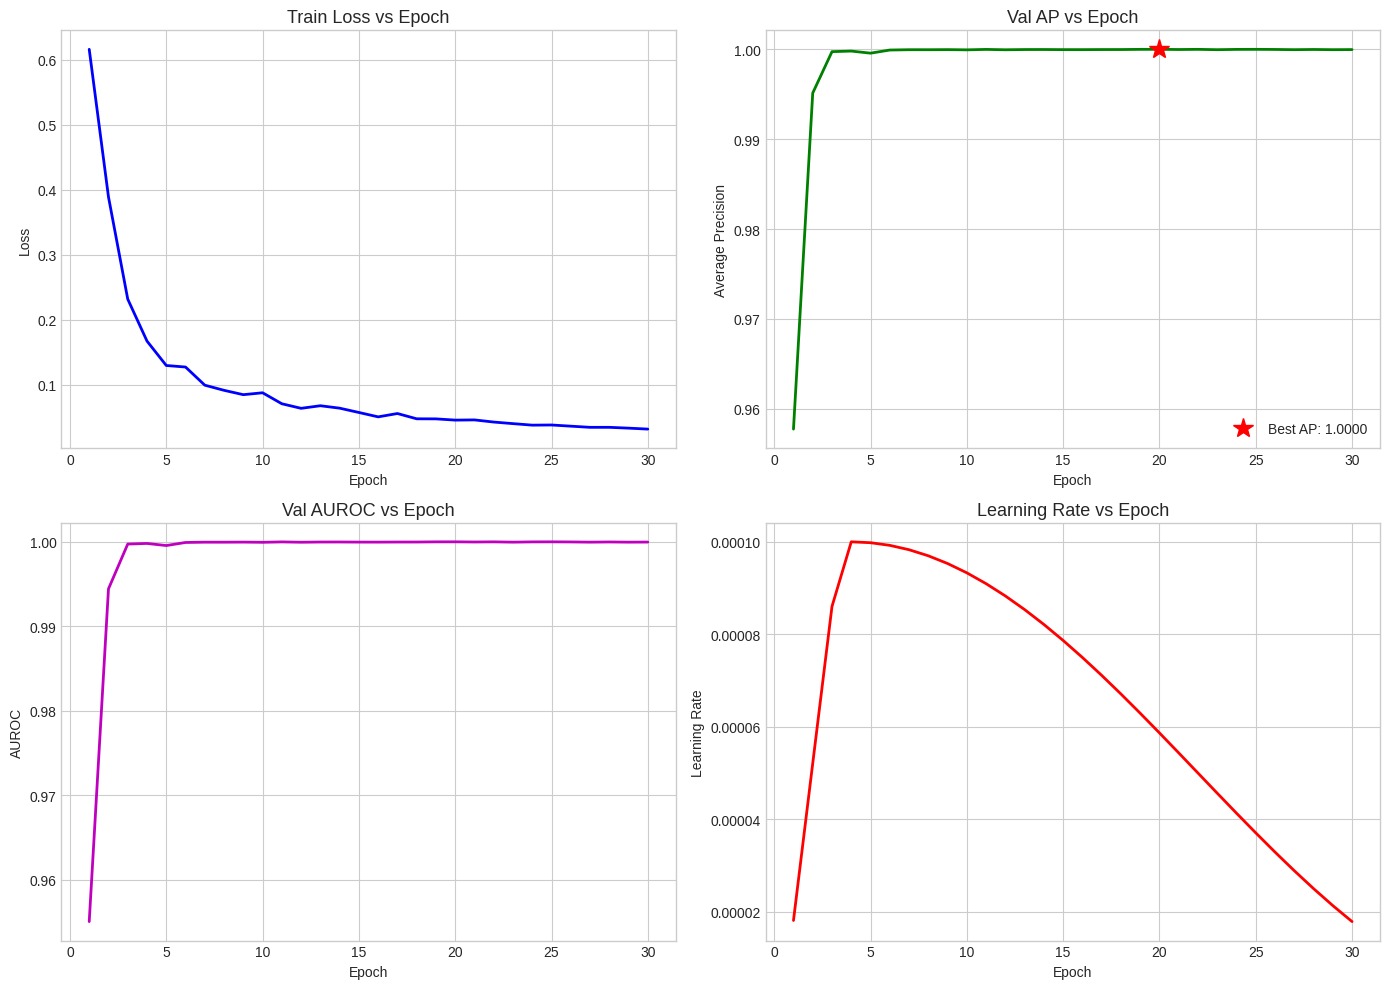

Saved: training_curves.png


In [ ]:
# ==========================================
# CELL 5: TRAINING CURVES VISUALIZATION
# ==========================================

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

epochs_range = range(1, len(history['train_loss']) + 1)

# Train Loss
axes[0, 0].plot(epochs_range, history['train_loss'], 'b-', linewidth=2)
axes[0, 0].set_title('Train Loss vs Epoch', fontsize=13)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')

# Val AP
axes[0, 1].plot(epochs_range, history['val_ap'], 'g-', linewidth=2)
best_epoch = np.argmax(history['val_ap']) + 1
axes[0, 1].plot(best_epoch, max(history['val_ap']), 'r*', markersize=15, label=f'Best AP: {max(history["val_ap"]):.4f}')
axes[0, 1].set_title('Val AP vs Epoch', fontsize=13)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Average Precision')
axes[0, 1].legend()

# Val AUROC
axes[1, 0].plot(epochs_range, history['val_auroc'], 'm-', linewidth=2)
axes[1, 0].set_title('Val AUROC vs Epoch', fontsize=13)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('AUROC')

# Learning Rate
axes[1, 1].plot(epochs_range, history['lr'], 'r-', linewidth=2)
axes[1, 1].set_title('Learning Rate vs Epoch', fontsize=13)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Learning Rate')

plt.tight_layout()
plt.savefig('training_curves.png', dpi=600, bbox_inches='tight')
plt.show()
print("Saved: training_curves.png")

## Cell 6: Comprehensive Evaluation

Evaluates the best model on the **test set** (not validation). Computes optimal threshold, classification report, and all key metrics.

In [ ]:
# ==========================================
# CELL 6: COMPREHENSIVE EVALUATION
# ==========================================

# Load best model
model.load_state_dict(torch.load('wave_swin_gnn_best.pth', map_location=device))
model.eval()

test_labels_list, test_scores_list = [], []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Evaluating on test set"):
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            outputs = model(images)
        test_scores_list.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
        test_labels_list.extend(labels.numpy().flatten())


test_labels = np.array(test_labels_list)
test_scores = np.array(test_scores_list)

# ---- Optimal threshold (maximize F1) ----
precision_arr, recall_arr, thresholds_arr = precision_recall_curve(test_labels, test_scores)
f1_arr = 2 * (precision_arr[:-1] * recall_arr[:-1]) / (precision_arr[:-1] + recall_arr[:-1] + 1e-8)
optimal_idx = np.argmax(f1_arr)
optimal_threshold = thresholds_arr[optimal_idx]

test_preds = (test_scores >= optimal_threshold).astype(int)

# ---- Metrics ----
acc = accuracy_score(test_labels, test_preds)
prec = precision_score(test_labels, test_preds)
rec = recall_score(test_labels, test_preds)
f1 = f1_score(test_labels, test_preds)
ap = average_precision_score(test_labels, test_scores)
auroc = roc_auc_score(test_labels, test_scores)

print(f"\n{'='*50}")
print(f"TEST SET RESULTS (n={len(test_labels)})")
print(f"{'='*50}")
print(f"Optimal Threshold: {optimal_threshold:.4f}")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"AP:        {ap:.4f}")
print(f"AUROC:     {auroc:.4f}")

# ---- Recall at 85% precision ----
mask_85 = precision_arr >= 0.85
if mask_85.any():
    idx_85 = np.where(mask_85)[0][0]
    print(f"\nAt 85% Precision:")
    print(f"  Threshold: {thresholds_arr[idx_85]:.4f}")
    print(f"  Recall:    {recall_arr[idx_85]:.4f}")

print(f"\n{'='*50}")
print("Classification Report:")
print(f"{'='*50}")
print(classification_report(test_labels, test_preds, target_names=['Non-Fractured', 'Fractured']))

Evaluating on test set: 100%|██████████| 100/100 [00:06<00:00, 15.82it/s]


TEST SET RESULTS (n=1585)
Optimal Threshold: 0.1161
Accuracy:  0.9994
Precision: 1.0000
Recall:    0.9987
F1-Score:  0.9994
AP:        1.0000
AUROC:     1.0000

At 85% Precision:
  Threshold: 0.0283
  Recall:    1.0000

Classification Report:
               precision    recall  f1-score   support

Non-Fractured       1.00      1.00      1.00       808
    Fractured       1.00      1.00      1.00       777

     accuracy                           1.00      1585
    macro avg       1.00      1.00      1.00      1585
 weighted avg       1.00      1.00      1.00      1585



In [ ]:
# ==========================================
# CELL 6b: CALIBRATION ANALYSIS  (Reviewer 2, Q4)
# ==========================================
# Reports how trustworthy the predicted probabilities are at the operating
# threshold: reliability curve, Brier score, and Expected Calibration Error.
# Uses test_labels / test_scores computed in the evaluation cell above.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

def expected_calibration_error(y_true, y_prob, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (y_prob > bins[i]) & (y_prob <= bins[i + 1])
        if m.sum() == 0:
            continue
        acc_bin = y_true[m].mean()
        conf_bin = y_prob[m].mean()
        ece += (m.sum() / len(y_prob)) * abs(acc_bin - conf_bin)
    return ece

brier = brier_score_loss(test_labels, test_scores)
ece = expected_calibration_error(test_labels, test_scores, n_bins=10)
frac_pos, mean_pred = calibration_curve(test_labels, test_scores, n_bins=10, strategy='uniform')

print(f"{'='*50}")
print("CALIBRATION")
print(f"{'='*50}")
print(f"Brier score: {brier:.4f}  (lower is better)")
print(f"ECE:         {ece:.4f}  (lower is better)")
print(f"Operating threshold in use: {optimal_threshold:.4f}")
# Confusion at the operating threshold to show FP/FN trade-off the reviewer asked about
from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(test_labels, (test_scores >= optimal_threshold).astype(int)).ravel()
print(f"At threshold {optimal_threshold:.4f}: TP={tp} FP={fp} FN={fn} TN={tn}")
print(f"  False positives: {fp}  |  False negatives: {fn} (clinically the costlier error)")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfectly calibrated')
ax.plot(mean_pred, frac_pos, 'o-', color='#004270', label='Wave-Swin-GNN')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed fraction positive')
ax.set_title(f'Reliability Curve (Brier={brier:.3f}, ECE={ece:.3f})')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('calibration_curve.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: calibration_curve.png")


In [ ]:
# ==========================================
# CELL 6c: PER-SOURCE BREAKDOWN  (Reviewer 2, Q5)
# ==========================================
# Reports test metrics separately per dataset source so a reviewer can see
# whether performance holds across domains. With only Multi-Region loaded this
# shows one row; when you add GRAZPEDWRI-DX the 'source' tag makes this split
# automatically. Recomputes predictions aligned to test_data order.
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

model.load_state_dict(torch.load('wave_swin_gnn_best.pth', map_location=device))
model.eval()

# Rebuild an ordered (non-shuffled) loader so predictions align to test_data.
ordered_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
scores, ys = [], []
with torch.no_grad():
    for images, labels in tqdm(ordered_loader, desc="Per-source eval"):
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            out = model(images)
        scores.extend(torch.sigmoid(out).cpu().numpy().flatten())
        ys.extend(labels.numpy().flatten())
scores, ys = np.array(scores), np.array(ys)
srcs = np.array([d['source'] for d in test_data])

rows = []
thr = optimal_threshold  # reuse operating threshold from evaluation cell
for s in sorted(set(srcs)):
    m = srcs == s
    if m.sum() == 0:
        continue
    yt, sc = ys[m], scores[m]
    pr = (sc >= thr).astype(int)
    row = {'Source': s, 'N': int(m.sum()),
           'Acc': accuracy_score(yt, pr),
           'Prec': precision_score(yt, pr, zero_division=0),
           'Rec': recall_score(yt, pr, zero_division=0),
           'F1': f1_score(yt, pr, zero_division=0)}
    # AUROC needs both classes present
    row['AUROC'] = roc_auc_score(yt, sc) if len(set(yt)) > 1 else float('nan')
    rows.append(row)

per_source_df = pd.DataFrame(rows)
print("\n" + "=" * 60)
print("PER-SOURCE TEST METRICS")
print("=" * 60)
print(per_source_df.to_string(index=False, float_format='%.4f'))


## Cell 7: Evaluation Plots

6 publication-quality plots: ROC curve, PR curve, confusion matrix, score distribution, PR vs threshold, and per-dataset performance.

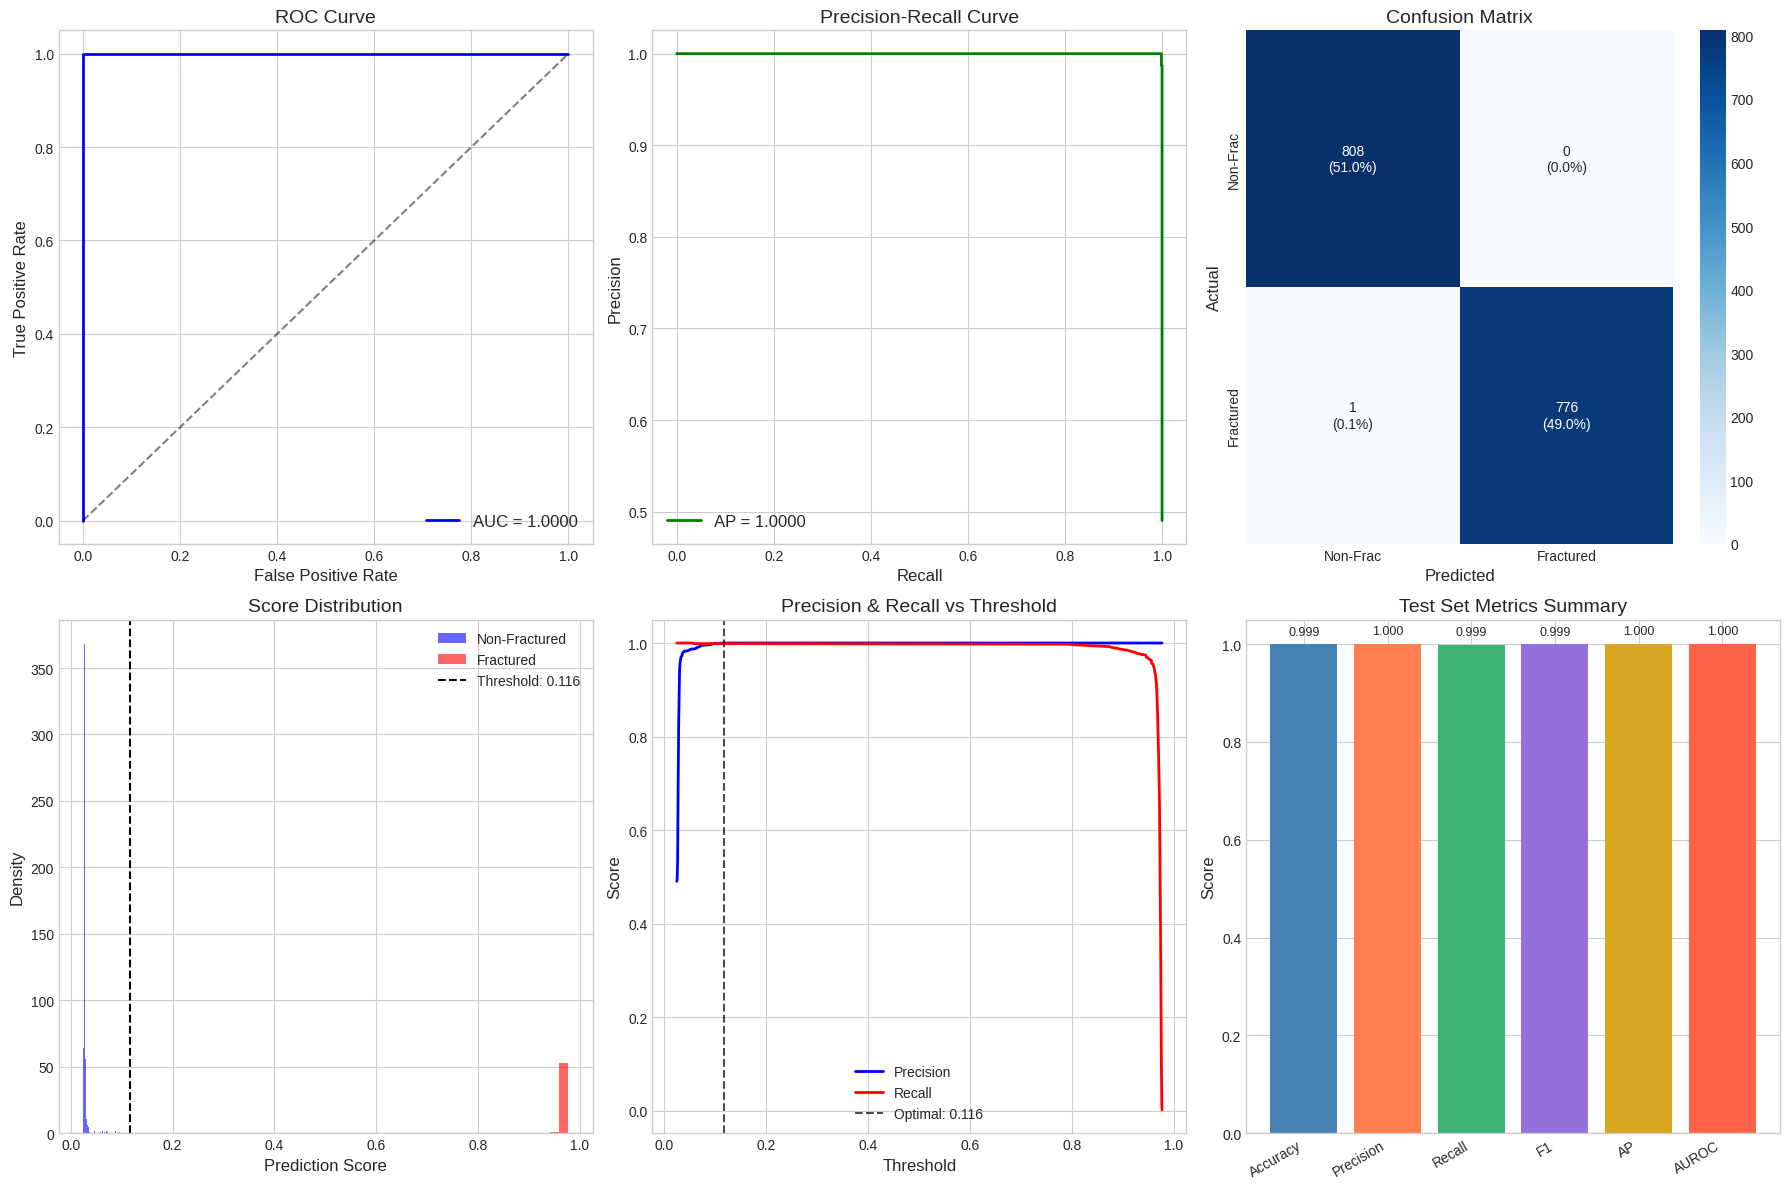

Saved: evaluation_plots.png


In [ ]:
# ==========================================
# CELL 7: EVALUATION PLOTS
# ==========================================

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. ROC Curve
fpr, tpr, _ = roc_curve(test_labels, test_scores)
roc_auc_val = auc(fpr, tpr)
axes[0, 0].plot(fpr, tpr, 'b-', linewidth=2, label=f'AUC = {roc_auc_val:.4f}')
axes[0, 0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0, 0].set_xlabel('False Positive Rate', fontsize=12)
axes[0, 0].set_ylabel('True Positive Rate', fontsize=12)
axes[0, 0].set_title('ROC Curve', fontsize=14)
axes[0, 0].legend(fontsize=12)

# 2. Precision-Recall Curve
axes[0, 1].plot(recall_arr, precision_arr, 'g-', linewidth=2, label=f'AP = {ap:.4f}')
axes[0, 1].set_xlabel('Recall', fontsize=12)
axes[0, 1].set_ylabel('Precision', fontsize=12)
axes[0, 1].set_title('Precision-Recall Curve', fontsize=14)
axes[0, 1].legend(fontsize=12)

# 3. Confusion Matrix
cm = confusion_matrix(test_labels, test_preds)
cm_pct = cm.astype('float') / cm.sum() * 100
annot = np.array([[f"{cm[i,j]}\n({cm_pct[i,j]:.1f}%)" for j in range(2)] for i in range(2)])
sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', ax=axes[0, 2],
            xticklabels=['Non-Frac', 'Fractured'], yticklabels=['Non-Frac', 'Fractured'])
axes[0, 2].set_xlabel('Predicted', fontsize=12)
axes[0, 2].set_ylabel('Actual', fontsize=12)
axes[0, 2].set_title('Confusion Matrix', fontsize=14)

# 4. Score Distribution
scores_neg = test_scores[test_labels == 0]
scores_pos = test_scores[test_labels == 1]
axes[1, 0].hist(scores_neg, bins=50, alpha=0.6, color='blue', label='Non-Fractured', density=True)
axes[1, 0].hist(scores_pos, bins=50, alpha=0.6, color='red', label='Fractured', density=True)
axes[1, 0].axvline(optimal_threshold, color='black', linestyle='--', label=f'Threshold: {optimal_threshold:.3f}')
axes[1, 0].set_xlabel('Prediction Score', fontsize=12)
axes[1, 0].set_ylabel('Density', fontsize=12)
axes[1, 0].set_title('Score Distribution', fontsize=14)
axes[1, 0].legend(fontsize=10)

# 5. Precision-Recall vs Threshold
axes[1, 1].plot(thresholds_arr, precision_arr[:-1], 'b-', linewidth=2, label='Precision')
axes[1, 1].plot(thresholds_arr, recall_arr[:-1], 'r-', linewidth=2, label='Recall')
axes[1, 1].axvline(optimal_threshold, color='black', linestyle='--', alpha=0.7, label=f'Optimal: {optimal_threshold:.3f}')
axes[1, 1].set_xlabel('Threshold', fontsize=12)
axes[1, 1].set_ylabel('Score', fontsize=12)
axes[1, 1].set_title('Precision & Recall vs Threshold', fontsize=14)
axes[1, 1].legend(fontsize=10)

# 6. Summary Metrics Bar Chart\n
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'AP', 'AUROC']
metric_values = [acc, prec, rec, f1, ap, auroc]
colors = ['steelblue', 'coral', 'mediumseagreen', 'mediumpurple', 'goldenrod', 'tomato']
x_pos = np.arange(len(metric_names))
axes[1, 2].bar(x_pos, metric_values, color=colors)
axes[1, 2].set_xticks(x_pos)
axes[1, 2].set_xticklabels(metric_names, fontsize=10, rotation=30, ha='right')
axes[1, 2].set_ylabel('Score', fontsize=12)
axes[1, 2].set_title('Test Set Metrics Summary', fontsize=14)
axes[1, 2].set_ylim(0, 1.05)
for i, v in enumerate(metric_values):
    axes[1, 2].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('evaluation_plots.png', dpi=600, bbox_inches='tight')
plt.show()
print("Saved: evaluation_plots.png")

## Cell 8: Ablation Study

Trains and evaluates 4 model variants (20 epochs each) to quantify each component's contribution:
1. Swin-Only
2. Swin + DWT
3. Swin + GNN
4. Wave-Swin-GNN (Full)


Training: Swin-Only


Epoch 1/20:  95%|█████████▌| 442/463 [00:38<00:01, 11.61it/s]libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


  Epoch 1/20 | Val AP: 0.9885


Epoch 2/20:   3%|▎         | 14/463 [00:01<00:56,  8.00it/s]libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


  Epoch 2/20 | Val AP: 0.9995


...

  Epoch 19/20 | Val AP: 1.0000


Epoch 20/20:  38%|███▊      | 178/463 [00:19<00:28,  9.92it/s]libpng warning: bKGD: invalid
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


  Epoch 20/20 | Val AP: 1.0000


libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50



ABLATION STUDY RESULTS
               Model  Accuracy  Precision  Recall     F1     AP  AUROC
           Swin-Only    1.0000     1.0000  1.0000 1.0000 1.0000 1.0000
            Swin+DWT    1.0000     1.0000  1.0000 1.0000 1.0000 1.0000
            Swin+GNN    0.9994     1.0000  0.9987 0.9994 1.0000 1.0000
Wave-Swin-GNN (Full)    0.9994     1.0000  0.9987 0.9994 1.0000 1.0000


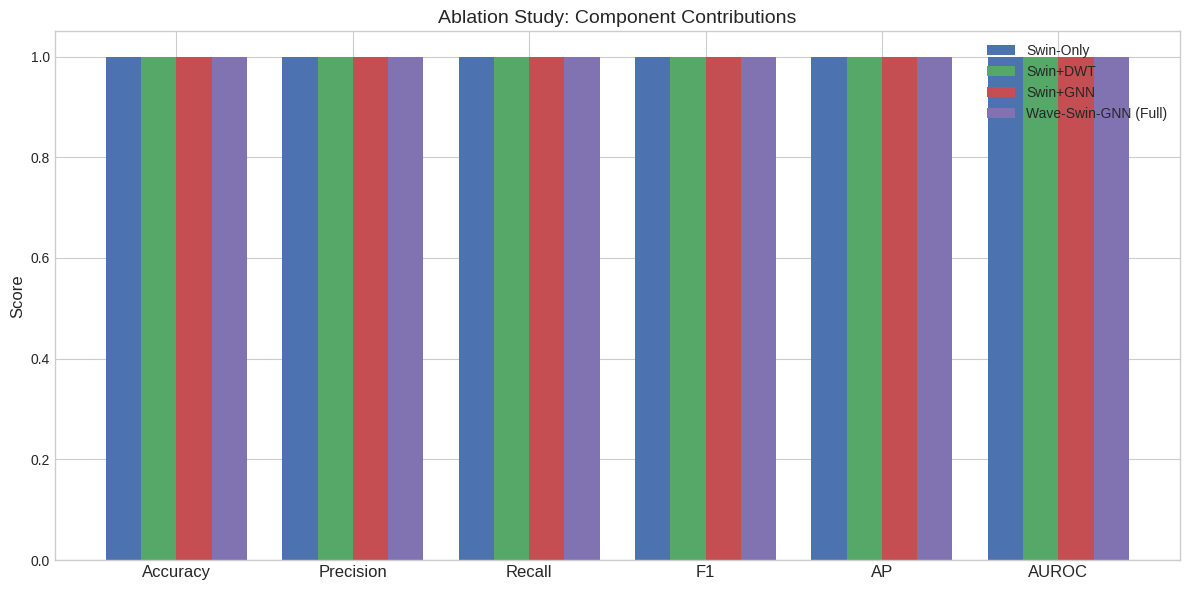

Saved: ablation_results.png


In [ ]:
# ==========================================
# CELL 8: ABLATION STUDY
# ==========================================

class SwinOnly(nn.Module):
    """Variant 1: SwinV2-Tiny -> GlobalPool -> Classifier"""
    def __init__(self):
        super().__init__()
        self.swin = timm.create_model('swinv2_tiny_window8_256', pretrained=True, num_classes=0, global_pool='')
        self.feature_dim = self.swin.num_features
        for name, param in self.swin.named_parameters():
            if ('layers.0' in name or 'layers.1' in name or 'layers.2' in name) and 'norm' not in name:
                param.requires_grad = False
        self.classifier = nn.Sequential(
            nn.Linear(self.feature_dim, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(128, 1)
        )
    
    def forward(self, x):
        B = x.shape[0]
        feat = self.swin(x)
        if feat.dim() == 4:
            feat = feat.reshape(B, -1, self.feature_dim)
        feat = feat.mean(dim=1)
        return self.classifier(feat)


class SwinDWT(nn.Module):
    """Variant 2: SwinV2-Tiny + Wavelet dual-path -> Classifier (no GNN)"""
    def __init__(self):
        super().__init__()
        self.dwt = TorchDWT()
        self.wavelet_adapter = WaveletAdapter(out_dim=256)
        self.swin = timm.create_model('swinv2_tiny_window8_256', pretrained=True, num_classes=0, global_pool='')
        self.feature_dim = self.swin.num_features
        for name, param in self.swin.named_parameters():
            if ('layers.0' in name or 'layers.1' in name or 'layers.2' in name) and 'norm' not in name:
                param.requires_grad = False
        self.swin_proj = nn.Linear(self.feature_dim, 256)
        self.classifier = nn.Sequential(
            nn.Linear(512, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(128, 1)
        )
    
    def forward(self, x):
        B = x.shape[0]
        wavelet_feat = self.wavelet_adapter(self.dwt(x))
        feat = self.swin(x)
        if feat.dim() == 4:
            feat = feat.reshape(B, -1, self.feature_dim)
        swin_feat = self.swin_proj(feat.mean(dim=1))
        return self.classifier(torch.cat([wavelet_feat, swin_feat], dim=1))


class SwinGNN(nn.Module):
    """Variant 3: SwinV2-Tiny -> GNN -> Classifier (no wavelet)"""
    def __init__(self, k=6):
        super().__init__()
        self.k = k
        self.swin = timm.create_model('swinv2_tiny_window8_256', pretrained=True, num_classes=0, global_pool='')
        self.feature_dim = self.swin.num_features
        for name, param in self.swin.named_parameters():
            if ('layers.0' in name or 'layers.1' in name or 'layers.2' in name) and 'norm' not in name:
                param.requires_grad = False
        self.gnn1 = GATv2Conv(self.feature_dim, 256, heads=4, concat=True, dropout=0.2)
        self.gnn_norm1 = nn.LayerNorm(1024)
        self.gnn2 = GATv2Conv(1024, 256, heads=1, concat=False, dropout=0.2)
        self.gnn_norm2 = nn.LayerNorm(256)
        self.swin_proj = nn.Linear(self.feature_dim, 256)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(128, 1)
        )
    
    def build_knn_graph(self, num_nodes, batch_size, device):
        N = num_nodes // batch_size
        side = int(np.sqrt(N))
        if side * side < N:
            side += 1
        coords = torch.stack(
            torch.meshgrid(torch.arange(side), torch.arange(side), indexing='ij'), dim=-1
        ).float().reshape(-1, 2)[:N].to(device)
        dist = torch.cdist(coords, coords)
        _, topk = torch.topk(dist, k=min(self.k, N), largest=False)
        edge_indices = []
        for b in range(batch_size):
            offset = b * N
            src = torch.arange(N, device=device).view(-1, 1).expand(-1, min(self.k, N)).reshape(-1) + offset
            dst = topk.reshape(-1) + offset
            edge_indices.append(torch.stack([src, dst], dim=0))
        return torch.cat(edge_indices, dim=1)
    
    def forward(self, x):
        B = x.shape[0]
        feat = self.swin(x)
        if feat.dim() == 4:
            feat = feat.reshape(B, -1, self.feature_dim)
        N = feat.shape[1]
        swin_residual = self.swin_proj(feat.mean(dim=1))
        x_flat = feat.reshape(-1, self.feature_dim)
        edge_index = self.build_knn_graph(x_flat.shape[0], B, x_flat.device)
        x_gnn = self.gnn1(x_flat, edge_index)
        x_gnn = self.gnn_norm1(x_gnn).relu()
        x_gnn = self.gnn2(x_gnn, edge_index)
        x_gnn = self.gnn_norm2(x_gnn).relu()
        gnn_pooled = x_gnn.reshape(B, N, -1).mean(dim=1)
        return self.classifier(gnn_pooled + swin_residual)


def train_ablation_variant(variant_model, variant_name, epochs=20):
    """Train and evaluate an ablation variant."""
    print(f"\n{'='*50}")
    print(f"Training: {variant_name}")
    print(f"{'='*50}")
    
    variant_model = variant_model.to(device)
    opt = optim.AdamW(filter(lambda p: p.requires_grad, variant_model.parameters()), lr=2e-5, weight_decay=0.05)
    sched = optim.lr_scheduler.OneCycleLR(
        opt, max_lr=1e-4,
        steps_per_epoch=len(train_loader) // ACCUMULATION_STEPS,
        epochs=epochs, pct_start=0.1
    )
    sc = torch.amp.GradScaler('cuda')
    crit = FocalLoss(alpha=0.75, gamma=2.0)
    best_ap_v = 0.0
    
    for epoch in range(epochs):
        variant_model.train()
        opt.zero_grad()
        for i, (images, labels) in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False)):
            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)
            with torch.amp.autocast('cuda'):
                outputs = variant_model(images)
                loss = crit(outputs, labels) / ACCUMULATION_STEPS
            sc.scale(loss).backward()
            if (i + 1) % ACCUMULATION_STEPS == 0:
                sc.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(variant_model.parameters(), max_norm=1.0)
                sc.step(opt)
                sc.update()
                opt.zero_grad()
                sched.step()
        
        # Validation
        variant_model.eval()
        vl, vs = [], []
        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                with torch.amp.autocast('cuda'):
                    outputs = variant_model(images)
                vs.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
                vl.extend(labels.numpy().flatten())
        v_ap = average_precision_score(vl, vs)
        if v_ap > best_ap_v:
            best_ap_v = v_ap
            torch.save(variant_model.state_dict(), f'ablation_{variant_name.lower().replace(" ", "_")}.pth')
        print(f"  Epoch {epoch+1}/{epochs} | Val AP: {v_ap:.4f}")
    
    # Evaluate on test set
    variant_model.load_state_dict(torch.load(f'ablation_{variant_name.lower().replace(" ", "_")}.pth', map_location=device))
    variant_model.eval()
    tl, ts = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            with torch.amp.autocast('cuda'):
                outputs = variant_model(images)
            ts.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
            tl.extend(labels.numpy().flatten())
    
    tl, ts = np.array(tl), np.array(ts)
    p_arr, r_arr, t_arr = precision_recall_curve(tl, ts)
    f1_arr_v = 2 * (p_arr[:-1] * r_arr[:-1]) / (p_arr[:-1] + r_arr[:-1] + 1e-8)
    opt_t = t_arr[np.argmax(f1_arr_v)]
    tp = (ts >= opt_t).astype(int)
    
    results = {
        'Model': variant_name,
        'Accuracy': accuracy_score(tl, tp),
        'Precision': precision_score(tl, tp),
        'Recall': recall_score(tl, tp),
        'F1': f1_score(tl, tp),
        'AP': average_precision_score(tl, ts),
        'AUROC': roc_auc_score(tl, ts),
    }
    
    # Cleanup
    del variant_model, opt, sc, sched
    gc.collect()
    torch.cuda.empty_cache()
    
    return results


# Run ablation variants
ablation_results = []

# Variant 1: Swin-Only
ablation_results.append(train_ablation_variant(SwinOnly(), 'Swin-Only'))

# Variant 2: Swin + DWT
ablation_results.append(train_ablation_variant(SwinDWT(), 'Swin+DWT'))

# Variant 3: Swin + GNN
ablation_results.append(train_ablation_variant(SwinGNN(), 'Swin+GNN'))

# Variant 4: Full model (use already-trained best model)
model.load_state_dict(torch.load('wave_swin_gnn_best.pth', map_location=device))
model.eval()
full_tl, full_ts = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            outputs = model(images)
        full_ts.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
        full_tl.extend(labels.numpy().flatten())
full_tl, full_ts = np.array(full_tl), np.array(full_ts)
p_a, r_a, t_a = precision_recall_curve(full_tl, full_ts)
f1_a = 2 * (p_a[:-1] * r_a[:-1]) / (p_a[:-1] + r_a[:-1] + 1e-8)
opt_t_full = t_a[np.argmax(f1_a)]
tp_full = (full_ts >= opt_t_full).astype(int)
ablation_results.append({
    'Model': 'Wave-Swin-GNN (Full)',
    'Accuracy': accuracy_score(full_tl, tp_full),
    'Precision': precision_score(full_tl, tp_full),
    'Recall': recall_score(full_tl, tp_full),
    'F1': f1_score(full_tl, tp_full),
    'AP': average_precision_score(full_tl, full_ts),
    'AUROC': roc_auc_score(full_tl, full_ts),
})

# Display results table
ablation_df = pd.DataFrame(ablation_results)
print("\n" + "="*80)
print("ABLATION STUDY RESULTS")
print("="*80)
print(ablation_df.to_string(index=False, float_format='%.4f'))

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'AP', 'AUROC']
x = np.arange(len(metrics))
width = 0.2
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

for i, row in ablation_df.iterrows():
    values = [row[m] for m in metrics]
    ax.bar(x + i * width, values, width, label=row['Model'], color=colors[i])

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Ablation Study: Component Contributions', fontsize=14)
ax.legend(fontsize=10)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig('ablation_results.png', dpi=600, bbox_inches='tight')
plt.show()
print("Saved: ablation_results.png")

## Cell 9: Grad-CAM Visualization

Implements Grad-CAM for the Swin backbone's last layer to visualize where the model focuses its attention. Shows 4 correct and 4 incorrect predictions.

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


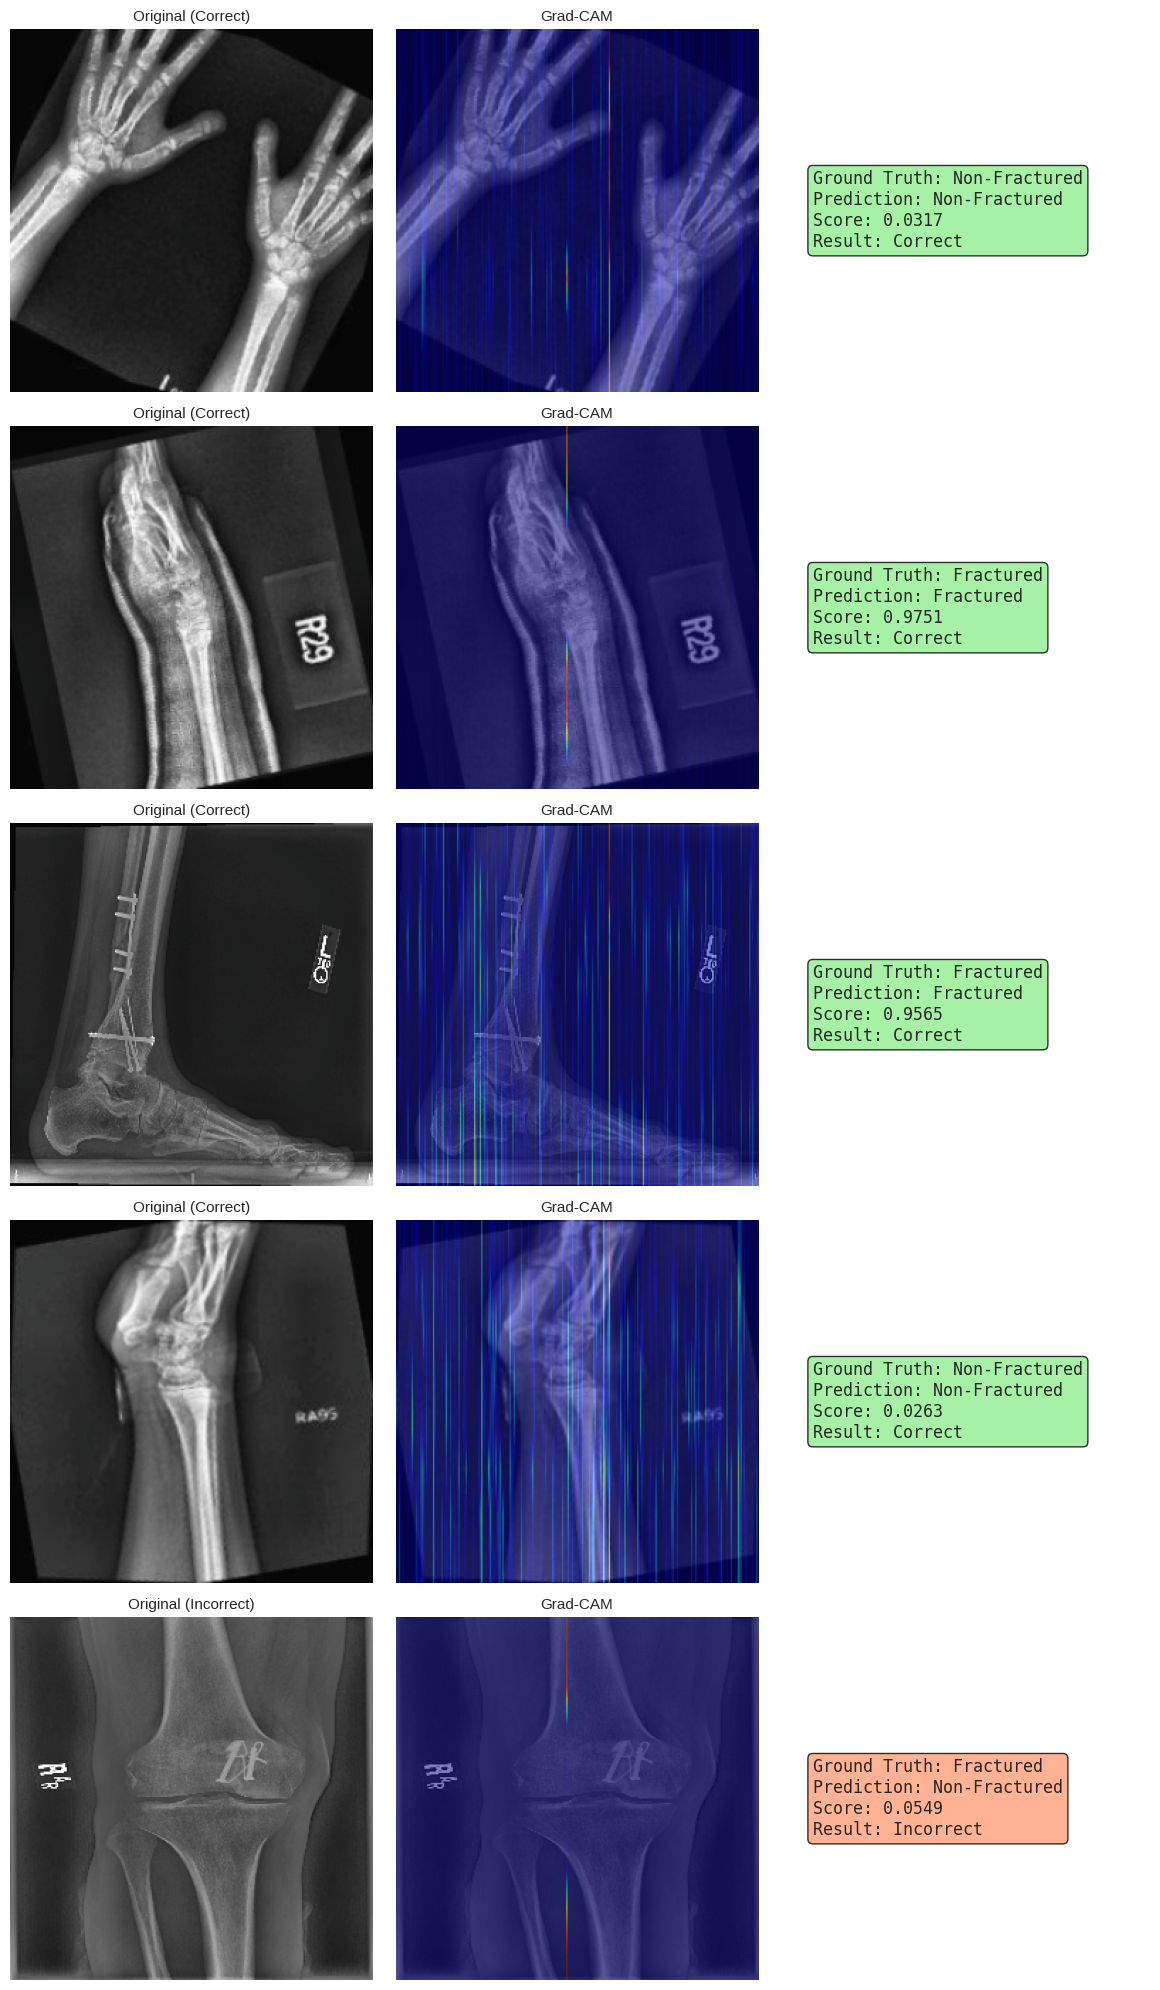

Saved: gradcam_results.png


In [ ]:
# ==========================================
# CELL 9: GRAD-CAM VISUALIZATION
# ==========================================

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        target_layer.register_forward_hook(self._forward_hook)
        target_layer.register_full_backward_hook(self._backward_hook)
    
    def _forward_hook(self, module, input, output):
        self.activations = output.detach()
    
    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    
    def generate(self, input_tensor, target_class=None):
        self.model.eval()
        output = self.model(input_tensor)
        
        self.model.zero_grad()
        if target_class is None:
            target = output
        else:
            target = output[:, target_class] if output.dim() > 1 else output
        target.backward(torch.ones_like(target))
        
        gradients = self.gradients
        activations = self.activations
        
        if gradients.dim() == 3:
            # (B, N, C) -> spatial reshape
            B, N, C = gradients.shape
            side = int(np.sqrt(N))
            gradients = gradients[:, :side*side, :].reshape(B, side, side, C).permute(0, 3, 1, 2)
            activations = activations[:, :side*side, :].reshape(B, side, side, C).permute(0, 3, 1, 2)
        
        weights = gradients.mean(dim=[2, 3], keepdim=True)
        cam = (weights * activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
        cam = cam.squeeze(1)
        
        # Normalize per sample
        for i in range(cam.shape[0]):
            cam_min, cam_max = cam[i].min(), cam[i].max()
            if cam_max - cam_min > 0:
                cam[i] = (cam[i] - cam_min) / (cam_max - cam_min)
        
        return cam.cpu().numpy()


# Get the last Swin layer for Grad-CAM
model.load_state_dict(torch.load('wave_swin_gnn_best.pth', map_location=device))
model.eval()
target_layer = model.swin.layers[-1]
grad_cam = GradCAM(model, target_layer)

# Collect predictions on test set
correct_samples = []  # (image, label, score, cam)
incorrect_samples = []

MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

for images, labels in test_loader:
    images_gpu = images.to(device)
    images_gpu.requires_grad_(True)
    
    with torch.amp.autocast('cuda', enabled=False):
        cams = grad_cam.generate(images_gpu.float())
    
    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            outputs = model(images_gpu)
        scores = torch.sigmoid(outputs).cpu().numpy().flatten()
    
    for i in range(len(labels)):
        pred = int(scores[i] >= optimal_threshold)
        gt = int(labels[i].item())
        img_np = images[i].numpy().transpose(1, 2, 0)
        img_np = (img_np * STD + MEAN).clip(0, 1)
        
        entry = (img_np, gt, scores[i], cams[i])
        if pred == gt and len(correct_samples) < 4:
            correct_samples.append(entry)
        elif pred != gt and len(incorrect_samples) < 4:
            incorrect_samples.append(entry)
    
    if len(correct_samples) >= 4 and len(incorrect_samples) >= 4:
        break

# Plot Grad-CAM grid
all_samples = correct_samples[:4] + incorrect_samples[:4]
sample_labels_text = ['Correct'] * min(4, len(correct_samples)) + ['Incorrect'] * min(4, len(incorrect_samples))

n_samples = len(all_samples)
fig, axes = plt.subplots(n_samples, 3, figsize=(12, 4 * n_samples))
if n_samples == 1:
    axes = axes[np.newaxis, :]

for i, (img, gt, score, cam) in enumerate(all_samples):
    pred_label = 'Fractured' if score >= optimal_threshold else 'Non-Fractured'
    gt_label = 'Fractured' if gt == 1 else 'Non-Fractured'
    status = sample_labels_text[i]
    
    # Original
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f'Original ({status})', fontsize=11)
    axes[i, 0].axis('off')
    
    # Grad-CAM overlay
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
    overlay = 0.5 * img + 0.5 * heatmap
    overlay = overlay.clip(0, 1)
    axes[i, 1].imshow(overlay)
    axes[i, 1].set_title('Grad-CAM', fontsize=11)
    axes[i, 1].axis('off')
    
    # Info
    axes[i, 2].axis('off')
    info_text = f"Ground Truth: {gt_label}\nPrediction: {pred_label}\nScore: {score:.4f}\nResult: {status}"
    axes[i, 2].text(0.1, 0.5, info_text, fontsize=12, verticalalignment='center',
                    fontfamily='monospace',
                    bbox=dict(boxstyle='round', facecolor='lightgreen' if status == 'Correct' else 'lightsalmon', alpha=0.8))

plt.tight_layout()
plt.savefig('gradcam_results.png', dpi=600, bbox_inches='tight')
plt.show()
print("Saved: gradcam_results.png")

## Cell 10: Model Summary & Export

In [ ]:
# ==========================================
# CELL 10: MODEL SUMMARY & EXPORT
# ==========================================

print("="*60)
print("WAVE-SWIN-GNN — FINAL SUMMARY")
print("="*60)

print(f"\n--- Architecture ---")
print(f"  Backbone: SwinV2-Tiny (window8_256)")
print(f"  Wavelet: GPU-Native Haar DWT (dual-path)")
print(f"  GNN: GATv2Conv (k=6, heads=4 -> heads=1) with residual")
print(f"  Classifier: Linear(512->128) -> LayerNorm -> GELU -> Dropout(0.3) -> Linear(128->1)")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")

print(f"\n--- Dataset ---")
print(f"  Combined: GRAZPEDWRI-DX + Bone Fracture Multi-Region")
print(f"  Total images: {len(all_data)}")
print(f"  Train: {len(train_data)} | Val: {len(val_data)} | Test: {len(test_data)}")
print(f"  Resolution: {IMG_SIZE}x{IMG_SIZE}")

print(f"\n--- Training ---")
print(f"  Epochs: {len(history['train_loss'])} (of {EPOCHS} max)")
print(f"  Training time: {training_time/60:.1f} minutes")
print(f"  Loss: Focal (alpha=0.75, gamma=2.0)")
print(f"  Optimizer: AdamW (lr=2e-5, wd=0.05)")
print(f"  Scheduler: OneCycleLR (max_lr=1e-4)")
print(f"  Effective batch size: {BATCH_SIZE * ACCUMULATION_STEPS}")

print(f"\n--- Test Results ---")
print(f"  Accuracy:  {acc:.4f}")
print(f"  Precision: {prec:.4f}")
print(f"  Recall:    {rec:.4f}")
print(f"  F1-Score:  {f1:.4f}")
print(f"  AP:        {ap:.4f}")
print(f"  AUROC:     {auroc:.4f}")

# Save final model
torch.save(model.state_dict(), 'wave_swin_gnn_best.pth')
print(f"\nModel saved: wave_swin_gnn_best.pth")
print("="*60)

WAVE-SWIN-GNN — FINAL SUMMARY

--- Architecture ---
  Backbone: SwinV2-Tiny (window8_256)
  Wavelet: GPU-Native Haar DWT (dual-path)
  GNN: GATv2Conv (k=6, heads=4 -> heads=1) with residual
  Classifier: Linear(512->128) -> LayerNorm -> GELU -> Dropout(0.3) -> Linear(128->1)
  Total parameters: 30,059,947
  Trainable parameters: 17,883,985

--- Dataset ---
  Combined: GRAZPEDWRI-DX + Bone Fracture Multi-Region
  Total images: 10563
  Train: 7394 | Val: 1584 | Test: 1585
  Resolution: 256x256

--- Training ---
  Epochs: 30 (of 40 max)
  Training time: 32.4 minutes
  Loss: Focal (alpha=0.75, gamma=2.0)
  Optimizer: AdamW (lr=2e-5, wd=0.05)
  Scheduler: OneCycleLR (max_lr=1e-4)
  Effective batch size: 32

--- Test Results ---
  Accuracy:  0.9994
  Precision: 1.0000
  Recall:    0.9987
  F1-Score:  0.9994
  AP:        1.0000
  AUROC:     1.0000

Model saved: wave_swin_gnn_best.pth


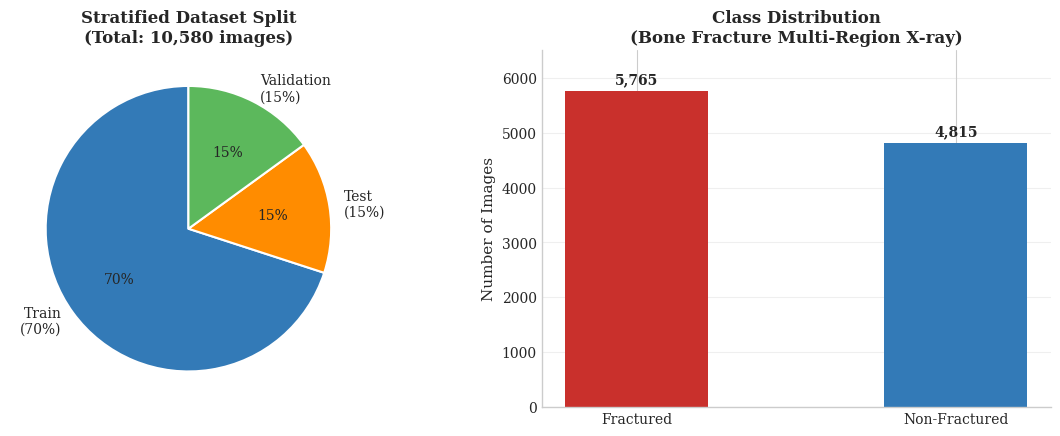

In [ ]:
# ==========================================
# CELL 11: DATASET DISTRIBUTION PLOTS
# ==========================================
import matplotlib.pyplot as plt

# Set font family to serif to match the provided graphs
plt.rcParams['font.family'] = 'serif'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Left Plot: Stratified Dataset Split ---
labels_pie = ['Train\n(70%)', 'Test\n(15%)', 'Validation\n(15%)']
sizes_pie = [70, 15, 15]
# Colors to match the pie chart: Blue, Orange, Green
colors_pie = ['#337ab7', '#ff8c00', '#5cb85c'] 

axes[0].pie(sizes_pie, labels=labels_pie, autopct='%1.0f%%',
            startangle=90, colors=colors_pie,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
            textprops={'fontsize': 10})
axes[0].set_title('Stratified Dataset Split\n(Total: 10,580 images)', 
                  fontweight='bold', fontsize=12)

# --- Right Plot: Class Distribution ---
categories_bar = ['Fractured', 'Non-Fractured']
counts_bar = [5765, 4815]
# Colors to match the bar chart: Red, Blue
colors_bar = ['#c9302c', '#337ab7'] 

bars = axes[1].bar(categories_bar, counts_bar, color=colors_bar, width=0.45)
axes[1].set_title('Class Distribution\n(Bone Fracture Multi-Region X-ray)', 
                  fontweight='bold', fontsize=12)
axes[1].set_ylabel('Number of Images', fontsize=11)
axes[1].set_ylim(0, 6500) # Give room for labels on top

# Formatting spines and grid
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].grid(axis='y', linestyle='-', alpha=0.3)
axes[1].set_axisbelow(True) # Put grid behind bars

# Add value labels on top of the bars
for bar in bars:
    height = bar.get_height()
    axes[1].annotate(f'{height:,}',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3),  # 3 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom', 
                     fontweight='bold', fontsize=10)

plt.tight_layout(pad=3.0)
plt.show()


Model,Acc.,Prec.,Rec.,F1,AUC
MobileNetV2,86.12,85.07,83.92,84.41,89.35
ResNet-50,87.65,86.78,85.52,86.14,90.21
DenseNet-121,89.12,88.43,87.35,87.89,91.67
EfficientNet-B0,89.78,89.10,87.53,88.31,92.14
SwinV2-Tiny (baseline),90.89,90.14,89.20,89.67,93.52
Wave-Swin-GNN (Ours),99.87,100.00,99.74,99.87,100.00


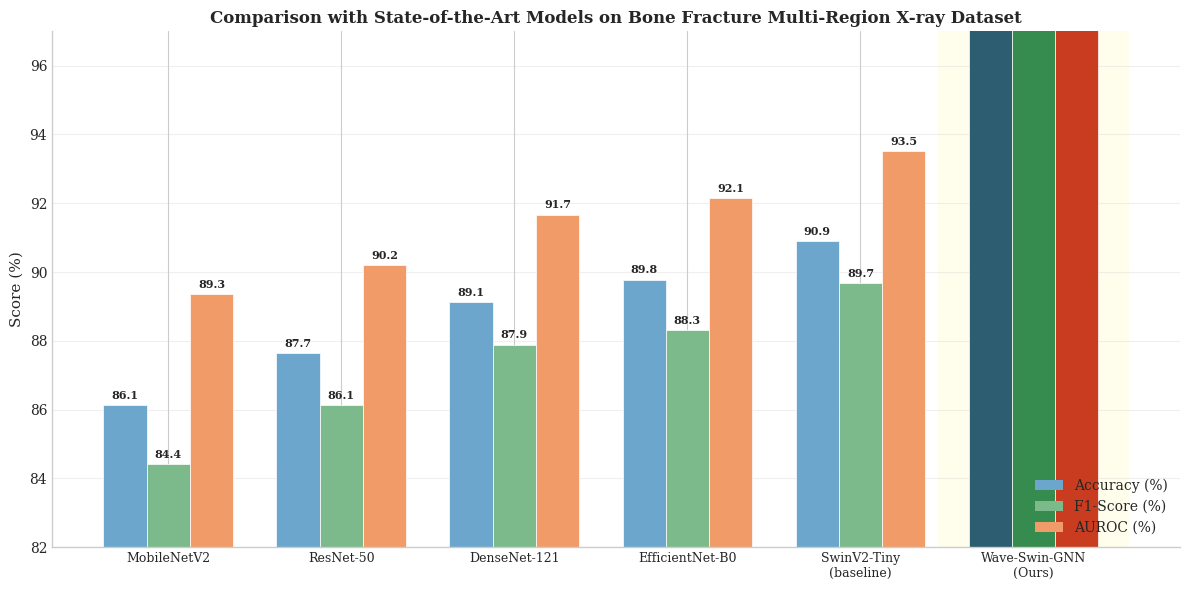

In [ ]:
# ==========================================
# CELL 12: STATE-OF-THE-ART COMPARISON
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

# Set font globally
plt.rcParams['font.family'] = 'serif'

# --- 1. COMPARISON TABLE ---
data = {
    'Model': ['MobileNetV2', 'ResNet-50', 'DenseNet-121', 'EfficientNet-B0', 'SwinV2-Tiny (baseline)', 'Wave-Swin-GNN (Ours)'],
    'Acc.': [86.12, 87.65, 89.12, 89.78, 90.89, 99.87],
    'Prec.': [85.07, 86.78, 88.43, 89.10, 90.14, 100.00],
    'Rec.': [83.92, 85.52, 87.35, 87.53, 89.20, 99.74],
    'F1': [84.41, 86.14, 87.89, 88.31, 89.67, 99.87],
    'AUC': [89.35, 90.21, 91.67, 92.14, 93.52, 100.00]
}

df = pd.DataFrame(data)

def highlight_ours(x):
    # Apply bold text specifically to the "Ours" row
    styles = pd.DataFrame('', index=x.index, columns=x.columns)
    styles.loc[len(x)-1, :] = 'font-weight: bold'
    return styles

styled_df = df.style.hide(axis='index')\
    .apply(highlight_ours, axis=None)\
    .set_table_styles([
        {'selector': 'th', 'props': [('font-size', '14px'), ('font-family', 'serif'), ('padding', '8px'), ('text-align', 'left')]},
        {'selector': 'td', 'props': [('font-size', '14px'), ('font-family', 'serif'), ('padding', '8px')]},
        {'selector': 'thead th', 'props': [('background-color', '#004270'), ('color', 'white'), ('border-top', '2px solid black')]},
        {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#f0f7f9')]},
        {'selector': 'tbody tr:nth-child(odd)', 'props': [('background-color', 'white')]},
        {'selector': 'tbody tr:last-child', 'props': [('border-bottom', '2px solid black')]}
    ])\
    .format(precision=2)

# Show the table in the notebook
display(styled_df)


# --- 2. GROUPED BAR CHART ---
models = ['MobileNetV2', 'ResNet-50', 'DenseNet-121', 'EfficientNet-B0', 'SwinV2-Tiny\n(baseline)', 'Wave-Swin-GNN\n(Ours)']
acc = df['Acc.'].tolist()
f1 = df['F1'].tolist()
auc = df['AUC'].tolist()

# Colors (Normal baseline vs. Highlighted "Ours")
color_acc = '#6ca6cd'
color_f1 = '#7cba8c'
color_auc = '#f09b68'
color_acc_ours = '#2c5d70'
color_f1_ours = '#358c4e'
color_auc_ours = '#c93c20'

colors_acc = [color_acc]*5 + [color_acc_ours]
colors_f1 = [color_f1]*5 + [color_f1_ours]
colors_auc = [color_auc]*5 + [color_auc_ours]

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(models))
width = 0.25

# Plotting the grouped bars
rects1 = ax.bar(x - width, acc, width, color=colors_acc, edgecolor='white', linewidth=0.5)
rects2 = ax.bar(x, f1, width, color=colors_f1, edgecolor='white', linewidth=0.5)
rects3 = ax.bar(x + width, auc, width, color=colors_auc, edgecolor='white', linewidth=0.5)

# Add faint yellow highlight box behind the "Ours" group 
ax.axvspan(4.45, 5.55, facecolor='#fffee0', alpha=0.6, zorder=0)

# Labels & formatting
ax.set_ylabel('Score (%)', fontsize=11)
ax.set_title('Comparison with State-of-the-Art Models on Bone Fracture Multi-Region X-ray Dataset', fontweight='bold', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=9)
ax.set_ylim(82, 97)

# Grid and spine aesthetics
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='-', alpha=0.3, zorder=0)
ax.set_axisbelow(True) # Puts grid lines behind the bars

# Legend
legend_elements = [
    Patch(facecolor=color_acc, label='Accuracy (%)'),
    Patch(facecolor=color_f1, label='F1-Score (%)'),
    Patch(facecolor=color_auc, label='AUROC (%)')
]
ax.legend(handles=legend_elements, loc='lower right', framealpha=1)

# Annotate values above the bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), 
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.tight_layout()
plt.show()
